# RPGM plugin: who calls what

A map of `addons/_rpgm_plugin/` as it stands on 2026-11-24.

**The short version**

- `plugin.gd` creates everything once and wires two signals. It does no work itself.
- The **dock** only answers "what is selected?".
- The **lambda queue editor** is the real UI. It lives inside the dock.
- The **text helper** is the only code that knows how to describe a lambda.
- Nothing draws itself after an edit. Every edit goes through undo, and undo tells every view to redraw.

Most functions here are never called by your code. Godot calls them (`_enter_tree`, `_can_handle`, `_update_property`) or a signal does.

## 1. The files

| File | Class | One job |
|---|---|---|
| `plugin.gd` | `EditorPlugin` | Register and unregister everything |
| `_rpgm_plugin_bottom_dock/..._bottom_dock.gd` + `.tscn` | `_RPGM_Plugin_Bottom_Dock` | Follow the selection, pick what to show |
| `_rpgm_plugin_lambda_queue/..._lambda_queue_editor.gd` | `_RPGM_Plugin_Lambda_Queue_Editor` | Tabs, toolbar, command list, values pane |
| `_rpgm_plugin_lambda_queue/..._lambda_text.gd` | `_RPGM_Plugin_Lambda_Text` | Name, summarise, list and create lambdas |
| `_rpgm_plugin_lambda_queue/..._lambda_queue_property.gd` | `_RPGM_Plugin_Lambda_Queue_Property` | The Inspector row for one queue |
| `_rpgm_plugin_inspector/..._script_inspector.gd` | `EditorInspectorPlugin` | Put that row into the Inspector for `_RPGM_Script` |
| `_rpgm_plugin_inspector/_rpgm_plugin_inspector.gd` | `EditorInspectorPlugin` | Quantise buttons in the Inspector for `_RPGM_Mover` |
| `_rpgm_plugin_main_screen/...` | `_RPGM_Plugin_Main_Screen` | The RPGM tab beside 2D / 3D. Its code returns early, so it is empty for now |

## 2. Startup: who creates whom

This happens once, when the plugin is enabled.

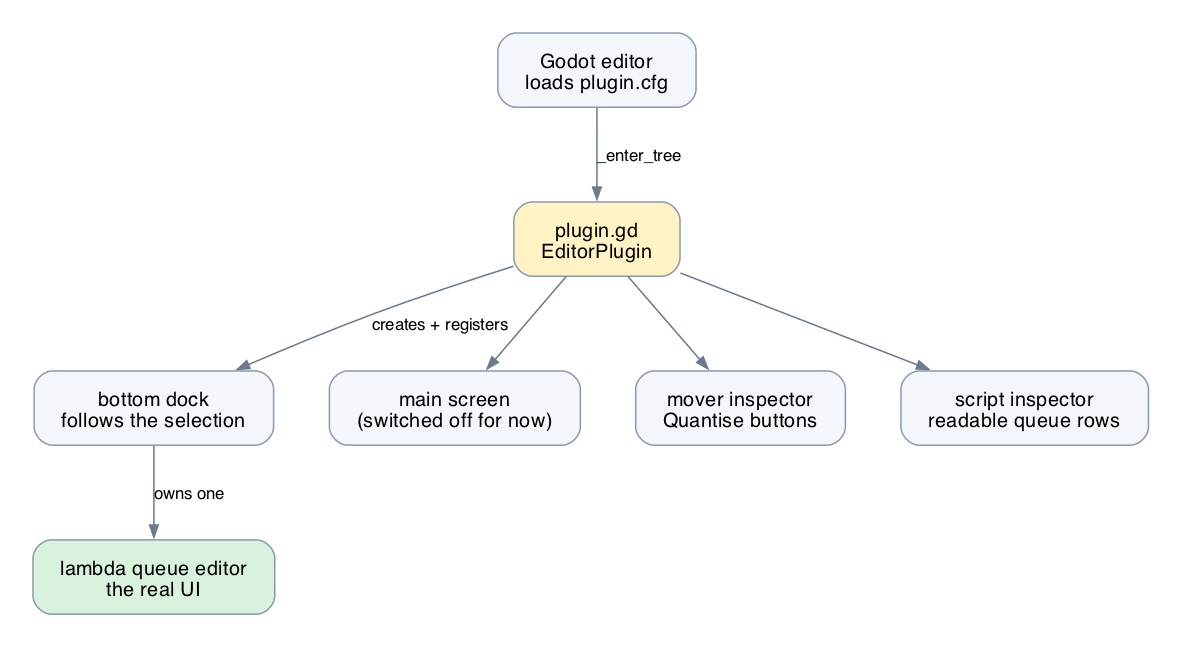

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  editor [label="Godot editor\nloads plugin.cfg"];
  plugin [label="plugin.gd\nEditorPlugin", fillcolor="#fff3c4"];
  dock [label="bottom dock\nfollows the selection"];
  main [label="main screen\n(switched off for now)"];
  mover [label="mover inspector\nQuantise buttons"];
  script [label="script inspector\nreadable queue rows"];
  queue [label="lambda queue editor\nthe real UI", fillcolor="#d9f2dd"];
  editor -> plugin [label="_enter_tree"];
  plugin -> dock [label="creates + registers"];
  plugin -> main;
  plugin -> mover;
  plugin -> script;
  dock -> queue [label="owns one"];
}
```

</details>

`plugin.gd` `_enter_tree` also makes two connections. They are the only links between the parts:

| Signal | From | To | Effect |
|---|---|---|---|
| `bottom_dock_requested` | dock | `make_bottom_panel_item_visible` | The RPGM panel pops up |
| `edit_requested` | script inspector | `dock.show_queue` | The Inspector's Edit button opens the dock |

`_exit_tree` removes the same instances it added.

## 3. Flow A: you select a node

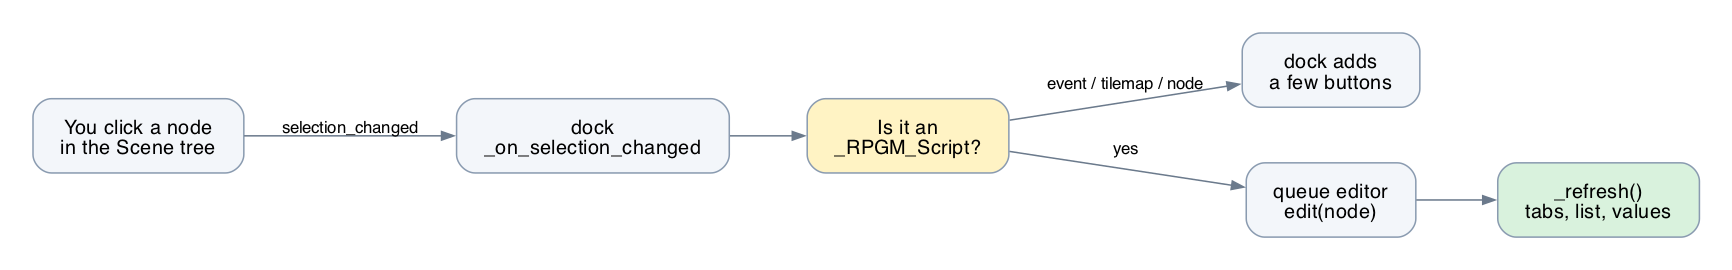

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  click [label="You click a node\nin the Scene tree"];
  sel [label="dock\n_on_selection_changed"];
  q [label="Is it an\n_RPGM_Script?", fillcolor="#fff3c4"];
  buttons [label="dock adds\na few buttons"];
  edit [label="queue editor\nedit(node)"];
  refresh [label="_refresh()\ntabs, list, values", fillcolor="#d9f2dd"];
  click -> sel [label="selection_changed"];
  sel -> q;
  q -> edit [label="yes"];
  q -> buttons [label="event / tilemap / node"];
  edit -> refresh;
}
```

</details>

The dock checks the node against each type in turn, so one node can match several:

| Node is a... | Dock calls | Result |
|---|---|---|
| `_RPGM_Node` | `_on_rpgm_node_node_selected` | "Describe _RPGM_Node" button |
| `_RPGM_Event` | `_on_rpgm_event_node_selected` | Two Quantise buttons |
| `TileMapLayer` | `_on_rpgm_tilemap_node_selected` | "Describe Tilemap" button |
| `_RPGM_Script` | `_on_rpgm_script_node_selected` | `_queue_editor.edit(node)`, then raises the dock |

Inside `edit(node)` the queue editor asks the text helper for `queue_properties(node)` (that is where the four tabs come from), selects the first command and calls `_refresh()`.

## 4. Flow B: you edit something in the dock

This loop is the heart of the plugin. Read it once and the rest of the queue editor falls into place.

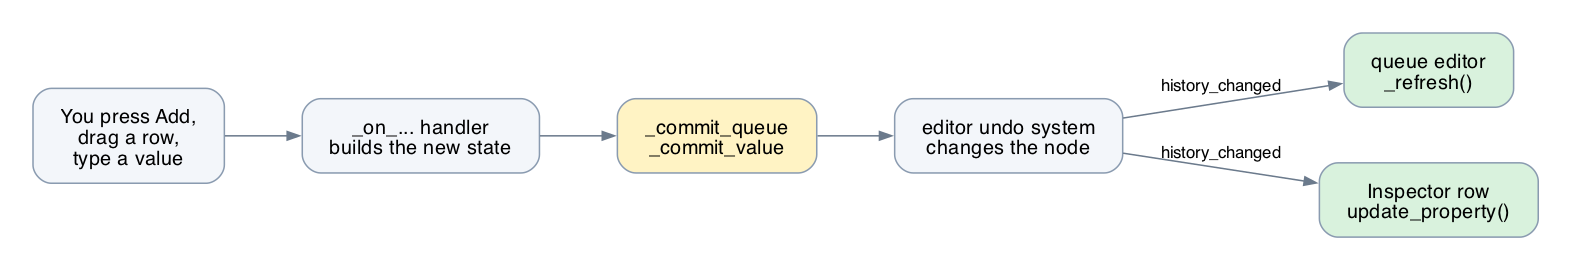

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  act [label="You press Add,\ndrag a row,\ntype a value"];
  handler [label="_on_... handler\nbuilds the new state"];
  commit [label="_commit_queue\n_commit_value", fillcolor="#fff3c4"];
  undo [label="editor undo system\nchanges the node"];
  dock [label="queue editor\n_refresh()", fillcolor="#d9f2dd"];
  row [label="Inspector row\nupdate_property()", fillcolor="#d9f2dd"];
  act -> handler -> commit -> undo;
  undo -> dock [label="history_changed"];
  undo -> row [label="history_changed"];
}
```

</details>

| Step | Functions | Rule |
|---|---|---|
| React | `_on_add_chosen`, `_on_duplicate_pressed`, `_on_move_pressed`, `_on_delete_pressed`, `_drop_row`, `_on_list_input`, `_on_value_changed` | Build the new state on a copy. Never touch the UI |
| Write | `_commit_queue` (the array), `_commit_value` (one value inside a lambda) | The only two functions that change data |
| Read | `_refresh` and its four parts: `_refresh_tabs`, `_refresh_toolbar`, `_refresh_list`, `_refresh_values` | The only place the panes are redrawn |

The same `history_changed` signal fires for Inspector edits, undo and redo. That is why the dock follows all three without any extra code.

Two handlers skip the loop because they change no data: `_on_tab_changed` and `_on_row_selected` only change what is being looked at, then refresh.

## 5. Flow C: the Inspector row

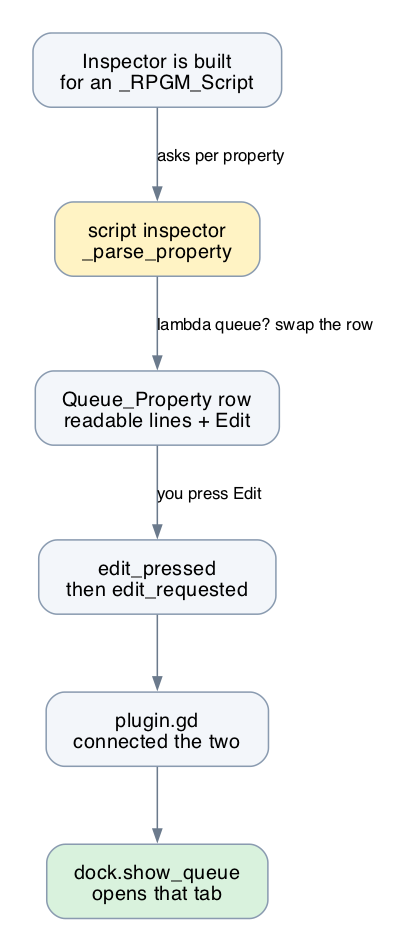

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  build [label="Inspector is built\nfor an _RPGM_Script"];
  parse [label="script inspector\n_parse_property", fillcolor="#fff3c4"];
  row [label="Queue_Property row\nreadable lines + Edit"];
  up [label="edit_pressed\nthen edit_requested"];
  plugin [label="plugin.gd\nconnected the two"];
  dock [label="dock.show_queue\nopens that tab", fillcolor="#d9f2dd"];
  build -> parse [label="asks per property"];
  parse -> row [label="lambda queue? swap the row"];
  row -> up [label="you press Edit"];
  up -> plugin -> dock;
}
```

</details>

| Who | Does what |
|---|---|
| Godot | Calls `_can_handle(object)`, then `_parse_property(...)` once per property |
| Script inspector | For a lambda queue: creates the row, returns `true` so the stock array editor is dropped |
| Row | `_update_property()` draws one line per command using the text helper |
| Row | Listens to `history_changed` too, so a value changed in the dock shows up here |
| Row to dock | `edit_pressed` (row) then `edit_requested` (inspector plugin) then `dock.show_queue` |

The row never knows the dock exists. Signals go up to `plugin.gd`, and `plugin.gd` calls down.

## 6. The text helper: who uses it

`_RPGM_Plugin_Lambda_Text` has only static functions and no state.

| Function | Answers | Used by |
|---|---|---|
| `queue_properties(node)` | Which properties are lambda queues? | Queue editor (tabs) |
| `is_lambda_queue(value)` | Is this array a lambda queue? | Script inspector, `queue_properties` |
| `friendly_name(lambda)` | "Show Messages" | Queue editor, Inspector row |
| `summary(lambda)` | The one-line description of its values | Queue editor, Inspector row |
| `exported_properties(lambda)` | Which values can be edited? | Queue editor (values pane), `summary` |
| `friendly_property_name(name)` | "On Action", "Scale" | Queue editor (tabs, value labels, undo names) |
| `lambda_classes()` | Every class that extends `_RPGM_Lambda` | Queue editor (Add menu) |
| `new_lambda(path)` | A fresh lambda of that class | Queue editor (Add) |

## 7. Who calls it: Godot, a signal, or us

| Called by | Examples |
|---|---|
| **Godot itself** | `_enter_tree`, `_exit_tree`, `_ready`, `_init`, `_can_handle`, `_parse_property`, `_update_property`, `_has_main_screen`, `_make_visible` |
| **An editor signal** | `selection_changed` to `dock._on_selection_changed`; `history_changed` to `queue_editor._refresh` and `row.update_property` |
| **A UI signal** | Button `pressed`, Tree `item_selected`, TabBar `tab_changed`, value editor `property_changed` |
| **Our own code** | `dock` calls `queue_editor.edit` and `show_queue`; everything calls the text helper |

Only three calls cross from one of our files into another: `edit`, `show_queue`, and the text helper functions.

## 8. A reading order

1. `plugin.gd`, top comment and `_enter_tree`: the table of contents.
2. `_rpgm_plugin_bottom_dock.gd`: short, shows the selection routing.
3. `_rpgm_plugin_lambda_queue_editor.gd` in this order: the header comment, `edit`, `_refresh`, `_commit_queue`, then one handler such as `_on_delete_pressed`. `_build_layout` at the bottom can be skimmed.
4. `_rpgm_plugin_lambda_text.gd`: look up functions as you meet them.
5. `_rpgm_plugin_script_inspector.gd` and `_rpgm_plugin_lambda_queue_property.gd`: the two small Inspector files.

The `# LESSON:` comments mark the ideas worth keeping when you tweak it.